# 결론 3 — H2 (버팀) 최종판

**H2: 조건이 같으면 의존 정류장은 마을버스 탑승 인원이 더 많았나?**

- 귀무가설: 조건이 같은 정류장끼리, 의존 정류장과 비의존 정류장의 마을버스 월 승차 인원은 차이가 없다
- 대립가설: 의존 정류장이 **더 많다**

**왜 "비중"을 버리고 "인원"으로 바꿨나**: 마을버스 승차 **비중** = 마을승차 ÷ 전체승차 인데,
의존 정류장은 정의상 멀리 가는 노선이 적으니 분모가 작아져 **비중이 저절로 커진다.**
그래서 이번엔 **인원(마을승차)** 을 본다.

- 대상: 월 승차 ≥ 75퍼센타일(13,482.5) + 지하철역 300m 밖 + **마을버스 노선 1개 이상** 서는 정류장
- 함정 확인: **마을 노선 수가 같은 층**(1 / 2 / 3+)끼리 다시 비교 (층 n<10이면 판단 보류)
- 보조: **전체 승차 4분위**로 층을 맞춰 다시 비교 (많이 타는 정류장이라 마을도 많은 건 아닌지)
- 견고성: **walk300**(도보 300m 합집합) 의존 정의로 반복

In [1]:
# 프로젝트 ROOT 찾아서 공통 경로·함수 불러오기 (경로 문자열은 src/paths.py에만)
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "CLAUDE.md").exists())
sys.path.insert(0, str(ROOT / "src"))
from paths import RAW, EXT, PROC, REPORTS

print("ROOT:", ROOT)

ROOT: C:\study\aix\aix_2


In [2]:
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

import biv_stats as bs
from bus_util import D_MAIN, P75

mpl.rcParams["font.family"] = "Malgun Gothic"
mpl.rcParams["axes.unicode_minus"] = False
sns.set_theme(style="whitegrid", font="Malgun Gothic", rc={"axes.unicode_minus": False})
pd.set_option("display.max_columns", 60)
pd.set_option("display.max_rows", 200)
pd.set_option("display.width", 240)

TARGET = "01278"          # 상명대정문
V = "마을승차"            # 마을버스 월 승차 인원

stop = pd.read_csv(PROC / "stop_metrics_subway.csv", encoding="utf-8-sig",
                   dtype={"버스정류장ARS번호": str, "1위노선": str})
sr = pd.read_csv(PROC / "stop_route.csv", encoding="utf-8-sig",
                 dtype={"ARS": str, "노선번호": str})
walk = pd.read_csv(PROC / "stop_walk.csv", encoding="utf-8-sig", dtype={"ARS": str})
print(stop.shape, sr.shape, walk.shape)

d = (stop.rename(columns={"버스정류장ARS번호": "ARS", "월승차": "정류장월승차"})
     [["ARS", "정류장명", "자치구", "정류장월승차", "멀리가는노선수", "마을노선수",
       V, "마을승차비중", "가까운역거리m"]].copy())
d = d.merge(walk[["ARS", "도보권_멀리노선수_300"]], on="ARS", how="left")

# 대상 = 승차 상위 25% + 역 300m 밖 + 마을 노선 1개 이상
pool = d[(d["정류장월승차"] >= P75) & (d["가까운역거리m"] > D_MAIN)
         & (d["마을노선수"] >= 1)].copy()
pool["구분"] = np.where(pool["멀리가는노선수"] <= 1, "의존", "비의존")
print(f"대상 정류장: {len(pool)}개 "
      f"(의존 {int((pool['구분'] == '의존').sum())} / "
      f"비의존 {int((pool['구분'] == '비의존').sum())})")
print(f"※ 마을 노선이 0개인 정류장은 비교가 불가능해 제외 "
      f"(승차·역 조건만 만족하는 정류장 "
      f"{int(((d['정류장월승차'] >= P75) & (d['가까운역거리m'] > D_MAIN)).sum())}개 중)")

(10615, 24) (33992, 7) (10606, 22)
대상 정류장: 459개 (의존 131 / 비의존 328)
※ 마을 노선이 0개인 정류장은 비교가 불가능해 제외 (승차·역 조건만 만족하는 정류장 1489개 중)


## 1. 메인 비교 — 마을버스 승차 인원

In [3]:
r_main = bs.group2(pool.loc[pool["구분"] == "의존", V],
                   pool.loc[pool["구분"] == "비의존", V],
                   "의존", "비의존", vname=V)
r_ratio = bs.group2(pool.loc[pool["구분"] == "의존", "마을승차비중"],
                    pool.loc[pool["구분"] == "비의존", "마을승차비중"],
                    "의존", "비의존", vname="마을승차비중")
print("※ 아래 '마을승차비중' 행은 함정을 보여주기 위한 참고용이다 (분모가 작아져 커진다)")
pd.DataFrame([r_main, r_ratio])[["변수", "방법", "n_의존", "n_비의존",
                                 "중앙값_의존", "중앙값_비의존",
                                 "평균_의존", "평균_비의존", "p표시", "별표",
                                 "정규성_의존", "정규성_비의존", "Levene"]]

※ 아래 '마을승차비중' 행은 함정을 보여주기 위한 참고용이다 (분모가 작아져 커진다)


,변수,방법,n_의존,n_비의존,중앙값_의존,중앙값_비의존,평균_의존,평균_비의존,p표시,별표,정규성_의존,정규성_비의존,Levene
0,마을승차,순위합 검정(W),131,328,15988.0,5033.0000,17912.1603,6410.2348,p<0.05,**,p<0.05,p<0.05,-
1,마을승차비중,순위합 검정(W),131,328,1.0,0.2069,0.8930,0.2377,p<0.05,**,p<0.05,p<0.05,-


In [4]:
print(f"[H2 메인] {V}: 의존 중앙값 {r_main['중앙값_의존']:,.0f} vs "
      f"비의존 {r_main['중앙값_비의존']:,.0f} "
      f"({r_main['방법']}, {r_main['p표시']} {r_main['별표'] or 'n.s.'})")
print(f"  귀무가설: {'기각' if r_main['유의'] else '기각 못함'}")
print(f"  배율: 의존 ÷ 비의존 = "
      f"{r_main['중앙값_의존'] / r_main['중앙값_비의존']:.2f}배")
print(f"\n[참고/함정] 마을승차비중: 의존 {r_ratio['중앙값_의존']:.3f} vs "
      f"비의존 {r_ratio['중앙값_비의존']:.3f} "
      f"({r_ratio['p표시']} {r_ratio['별표'] or 'n.s.'})")

[H2 메인] 마을승차: 의존 중앙값 15,988 vs 비의존 5,033 (순위합 검정(W), p<0.05 **)
  귀무가설: 기각
  배율: 의존 ÷ 비의존 = 3.18배

[참고/함정] 마을승차비중: 의존 1.000 vs 비의존 0.207 (p<0.05 **)


## 2. 함정 확인 — 마을 노선 수가 같은 층끼리

In [5]:
def layer_test(df, by, labels, vcol=V, min_n=10):
    rows = []
    for lab in labels:
        g = df[df[by] == lab]
        a = g.loc[g["구분"] == "의존", vcol]
        b = g.loc[g["구분"] == "비의존", vcol]
        rec = {"층": lab, "n_의존": len(a), "n_비의존": len(b)}
        if len(a) < min_n or len(b) < min_n:
            rec.update({"판단": f"보류 (n<{min_n})", "방법": "-", "중앙값_의존": None,
                        "중앙값_비의존": None, "p표시": "-", "별표": "-"})
        else:
            r = bs.group2(a, b, "의존", "비의존", vname=vcol)
            rec.update({"판단": "기각" if r["유의"] else "기각 못함",
                        "방법": r["방법"],
                        "중앙값_의존": r["중앙값_의존"],
                        "중앙값_비의존": r["중앙값_비의존"],
                        "p표시": r["p표시"], "별표": r["별표"] or "n.s."})
        rows.append(rec)
    return pd.DataFrame(rows)


pool["마을층"] = np.where(pool["마을노선수"] >= 3, "3개+",
                          pool["마을노선수"].astype(int).astype(str) + "개")
print("마을 노선 수 분포:")
print(pool.groupby(["마을층", "구분"]).size().unstack(fill_value=0).to_string())

lay_m = layer_test(pool, "마을층", ["1개", "2개", "3개+"])
lay_m

마을 노선 수 분포:
구분   비의존  의존
마을층         
1개   204  63
2개    97  47
3개+   27  21


,층,n_의존,n_비의존,판단,방법,중앙값_의존,중앙값_비의존,p표시,별표
0,1개,63,204,기각,순위합 검정(W),15891.0,3892.5,p<0.05,**
1,2개,47,97,기각,순위합 검정(W),15585.0,7959.0,p<0.05,**
2,3개+,21,27,기각,순위합 검정(W),16747.0,8625.0,p<0.05,**


## 3. 보조 — 전체 승차 4분위로 층 맞추기

In [6]:
pool["승차층"] = pd.qcut(pool["정류장월승차"], 4,
                         labels=["Q1(낮음)", "Q2", "Q3", "Q4(높음)"])
print("승차 4분위 경계:",
      [f"{v:,.0f}" for v in pool["정류장월승차"].quantile([0, .25, .5, .75, 1]).values])
print(pool.groupby(["승차층", "구분"], observed=True).size().unstack(fill_value=0).to_string())

lay_q = layer_test(pool, "승차층", ["Q1(낮음)", "Q2", "Q3", "Q4(높음)"])
lay_q

승차 4분위 경계: ['13,492', '16,130', '22,006', '30,894', '103,835']
구분      비의존  의존
승차층            
Q1(낮음)   62  53
Q2       69  46
Q3       94  20
Q4(높음)  103  12


,층,n_의존,n_비의존,판단,방법,중앙값_의존,중앙값_비의존,p표시,별표
0,Q1(낮음),53,62,기각,순위합 검정(W),14140.0,3247.0,p<0.05,**
1,Q2,46,69,기각,순위합 검정(W),17877.5,4422.0,p<0.05,**
2,Q3,20,94,기각,순위합 검정(W),23487.0,5466.5,p<0.05,**
3,Q4(높음),12,103,기각,순위합 검정(W),32948.0,7415.0,p<0.05,**


In [7]:
# 승차층 × 마을층 둘 다 맞춘 교차 층 (n>=10 인 칸만)
rows = []
for q in ["Q1(낮음)", "Q2", "Q3", "Q4(높음)"]:
    for ml in ["1개", "2개", "3개+"]:
        g = pool[(pool["승차층"] == q) & (pool["마을층"] == ml)]
        a = g.loc[g["구분"] == "의존", V]
        b = g.loc[g["구분"] == "비의존", V]
        if len(a) < 10 or len(b) < 10:
            continue
        r = bs.group2(a, b, "의존", "비의존", vname=V)
        rows.append({"승차층": q, "마을층": ml, "n_의존": len(a), "n_비의존": len(b),
                     "중앙값_의존": r["중앙값_의존"], "중앙값_비의존": r["중앙값_비의존"],
                     "방법": r["방법"], "p표시": r["p표시"],
                     "별표": r["별표"] or "n.s.",
                     "의존이 더 많나": "O" if r["중앙값_의존"] > r["중앙값_비의존"] else "X"})
cross = pd.DataFrame(rows)
print(f"n>=10 을 만족하는 교차 층: {len(cross)}칸 (12칸 중)")
cross

n>=10 을 만족하는 교차 층: 4칸 (12칸 중)

,승차층,마을층,n_의존,n_비의존,중앙값_의존,중앙값_비의존,방법,p표시,별표,의존이 더 많나
0,Q1(낮음),1개,25,43,13981.0,2664.0,순위합 검정(W),p<0.05,**,O
1,Q1(낮음),2개,20,14,14195.5,4478.0,순위합 검정(W),p<0.05,**,O
2,Q2,1개,27,45,17913.0,3467.0,순위합 검정(W),p<0.05,**,O
3,Q2,2개,12,20,17477.5,5766.0,순위합 검정(W),p<0.05,**,O


## 4. 견고성 — walk300 의존 정의로 반복

In [8]:
pool_w = pool.copy()
pool_w["구분"] = np.where(pool_w["도보권_멀리노선수_300"] <= 1, "의존", "비의존")
print(f"walk300 기준: 의존 {int((pool_w['구분'] == '의존').sum())} / "
      f"비의존 {int((pool_w['구분'] == '비의존').sum())}")

r_w = bs.group2(pool_w.loc[pool_w["구분"] == "의존", V],
                pool_w.loc[pool_w["구분"] == "비의존", V],
                "의존", "비의존", vname=V)
lay_mw = layer_test(pool_w, "마을층", ["1개", "2개", "3개+"])
print(f"[walk300] {V}: 의존 {r_w['중앙값_의존']:,.0f} vs "
      f"비의존 {r_w['중앙값_비의존']:,.0f} "
      f"({r_w['방법']}, {r_w['p표시']} {r_w['별표'] or 'n.s.'})")
lay_mw

walk300 기준: 의존 53 / 비의존 406
[walk300] 마을승차: 의존 16,747 vs 비의존 6,400 (순위합 검정(W), p<0.05 **)


,층,n_의존,n_비의존,판단,방법,중앙값_의존,중앙값_비의존,p표시,별표
0,1개,25,242,기각,순위합 검정(W),17093.0,4347.0,p<0.05,**
1,2개,23,121,기각,순위합 검정(W),17014.0,9790.0,p<0.05,**
2,3개+,5,43,보류 (n<10),-,NaN,NaN,-,-


In [9]:
summary = pd.DataFrame([
    {"버전": "d300 (메인)", "n_의존": r_main["n_의존"], "n_비의존": r_main["n_비의존"],
     "중앙값_의존": r_main["중앙값_의존"], "중앙값_비의존": r_main["중앙값_비의존"],
     "방법": r_main["방법"], "p표시": r_main["p표시"],
     "별표": r_main["별표"] or "n.s."},
    {"버전": "walk300 (견고성)", "n_의존": r_w["n_의존"], "n_비의존": r_w["n_비의존"],
     "중앙값_의존": r_w["중앙값_의존"], "중앙값_비의존": r_w["중앙값_비의존"],
     "방법": r_w["방법"], "p표시": r_w["p표시"], "별표": r_w["별표"] or "n.s."},
])
summary

,버전,n_의존,n_비의존,중앙값_의존,중앙값_비의존,방법,p표시,별표
0,d300 (메인),131,328,15988.0,5033.0,순위합 검정(W),p<0.05,**
1,walk300 (견고성),53,406,16747.0,6400.0,순위합 검정(W),p<0.05,**


## 5. 상명대정문

In [10]:
vil = sr[~sr["노선종류"].isin(["간선", "지선", "광역", "순환", "심야", "맞춤"])]
smd_vil = vil[vil["ARS"] == TARGET][["노선번호", "노선종류", "월승차"]]
t = pool[pool["ARS"] == TARGET]
print("상명대정문 마을버스 노선:")
print(smd_vil.to_string(index=False))
if len(t):
    tv = float(t.iloc[0][V])
    print(f"\n상명대정문 마을버스 승차 합 {tv:,.0f} "
          f"(비의존 중앙값 {r_main['중앙값_비의존']:,.0f}의 "
          f"{tv / r_main['중앙값_비의존']:.1f}배, "
          f"의존 중앙값 {r_main['중앙값_의존']:,.0f}의 "
          f"{tv / r_main['중앙값_의존']:.1f}배)")
    rank = int((pool[V] > tv).sum()) + 1
    print(f"대상 {len(pool)}개 정류장 중 마을버스 승차 {rank}위")
else:
    print("\n상명대정문이 대상에 없다")

상명대정문 마을버스 노선:
 노선번호 노선종류   월승차
서대문08   마을 14163
 종로13   마을  3390

상명대정문 마을버스 승차 합 17,553 (비의존 중앙값 5,033의 3.5배, 의존 중앙값 15,988의 1.1배)
대상 459개 정류장 중 마을버스 승차 73위


## 6. 박스플롯

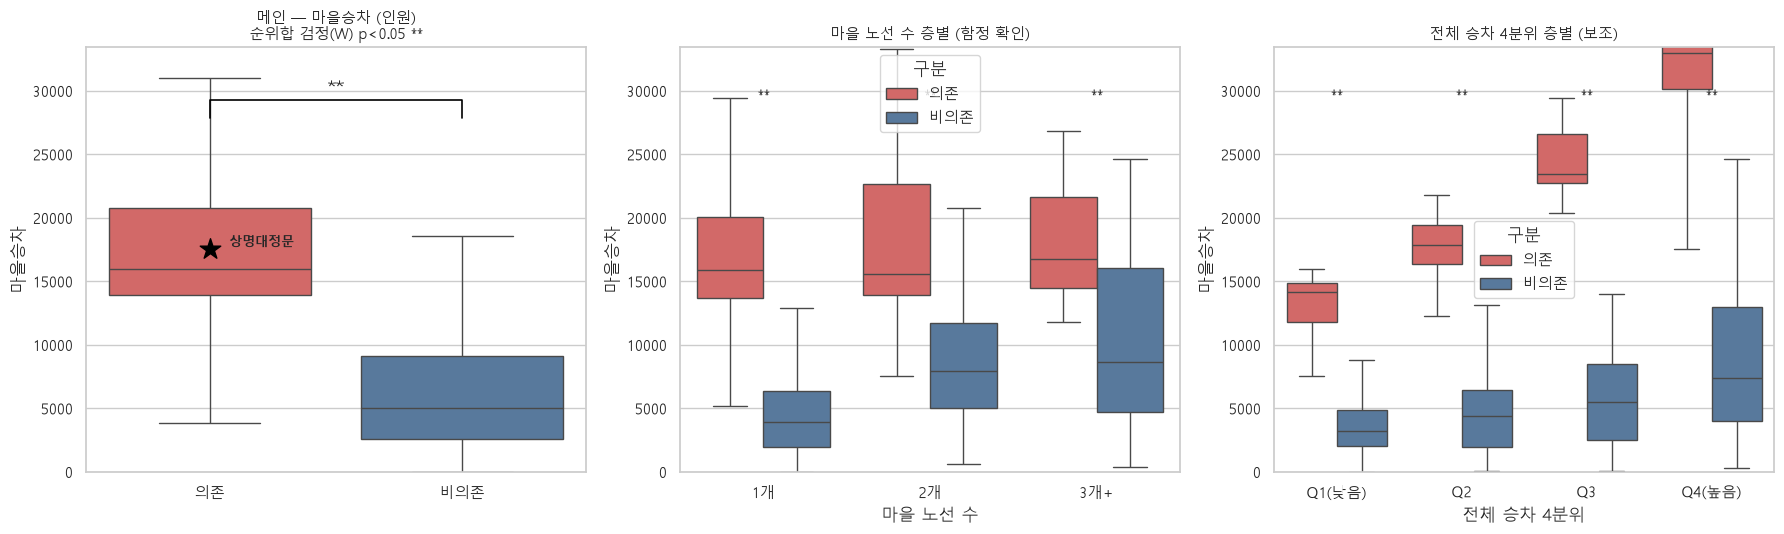

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))
PAL = {"의존": "#E45756", "비의존": "#4C78A8"}

sns.boxplot(data=pool, x="구분", y=V, order=["의존", "비의존"], hue="구분",
            palette=PAL, legend=False, showfliers=False, ax=axes[0])
y = pool[V].quantile(0.97)
axes[0].plot([0, 0, 1, 1], [y, y * 1.05, y * 1.05, y], lw=1.2, color="black")
axes[0].text(0.5, y * 1.07, r_main["별표"] or "n.s.", ha="center", fontsize=13)
axes[0].set_ylim(0, y * 1.2)
axes[0].set_title(f"메인 — {V} (인원)\n{r_main['방법']} {r_main['p표시']} "
                  f"{r_main['별표'] or 'n.s.'}", fontsize=11)
axes[0].set_xlabel("")
if len(t):
    axes[0].scatter([0], [min(tv, y * 1.15)], s=240, marker="*", color="black", zorder=10)
    axes[0].annotate("상명대정문", (0, min(tv, y * 1.15)), xytext=(14, 2),
                     textcoords="offset points", fontsize=9, weight="bold")

sns.boxplot(data=pool, x="마을층", y=V, order=["1개", "2개", "3개+"], hue="구분",
            hue_order=["의존", "비의존"], palette=PAL, showfliers=False, ax=axes[1])
for i, lab in enumerate(["1개", "2개", "3개+"]):
    s = lay_m[lay_m["층"] == lab].iloc[0]
    axes[1].text(i, y * 1.05, s["별표"] if s["별표"] != "-" else "보류",
                 ha="center", fontsize=11)
axes[1].set_ylim(0, y * 1.2)
axes[1].set_title(f"마을 노선 수 층별 (함정 확인)", fontsize=11)
axes[1].set_xlabel("마을 노선 수")

sns.boxplot(data=pool, x="승차층", y=V, order=["Q1(낮음)", "Q2", "Q3", "Q4(높음)"],
            hue="구분", hue_order=["의존", "비의존"], palette=PAL,
            showfliers=False, ax=axes[2])
for i, lab in enumerate(["Q1(낮음)", "Q2", "Q3", "Q4(높음)"]):
    s = lay_q[lay_q["층"] == lab].iloc[0]
    axes[2].text(i, y * 1.05, s["별표"] if s["별표"] != "-" else "보류",
                 ha="center", fontsize=11)
axes[2].set_ylim(0, y * 1.2)
axes[2].set_title("전체 승차 4분위 층별 (보조)", fontsize=11)
axes[2].set_xlabel("전체 승차 4분위")
plt.tight_layout()
plt.show()

## 결론 (H2)

In [12]:
print(f"1) 메인: {V} 의존 {r_main['중앙값_의존']:,.0f} vs 비의존 "
      f"{r_main['중앙값_비의존']:,.0f} ({r_main['p표시']} "
      f"{r_main['별표'] or 'n.s.'}) → 귀무가설 "
      f"{'기각' if r_main['유의'] else '기각 못함'}")
ok_m = lay_m[(lay_m["별표"].isin(["*", "**"]))]
print(f"2) 마을 노선 수 층: 판단 가능 "
      f"{int((lay_m['판단'] != f'보류 (n<10)').sum())}/3층, 그중 유의 {len(ok_m)}층")
ok_q = lay_q[(lay_q["별표"].isin(["*", "**"]))]
print(f"3) 승차 4분위 층: 판단 가능 "
      f"{int((lay_q['판단'] != f'보류 (n<10)').sum())}/4층, 그중 유의 {len(ok_q)}층")
print(f"4) 교차 층(승차×마을) n>=10: {len(cross)}칸, 유의 "
      f"{int(cross['별표'].isin(['*', '**']).sum()) if len(cross) else 0}칸, "
      f"의존이 더 많은 칸 "
      f"{int((cross['의존이 더 많나'] == 'O').sum()) if len(cross) else 0}칸")
print(f"5) walk300: 의존 {r_w['중앙값_의존']:,.0f} vs 비의존 "
      f"{r_w['중앙값_비의존']:,.0f} ({r_w['p표시']} {r_w['별표'] or 'n.s.'})")

1) 메인: 마을승차 의존 15,988 vs 비의존 5,033 (p<0.05 **) → 귀무가설 기각
2) 마을 노선 수 층: 판단 가능 3/3층, 그중 유의 3층
3) 승차 4분위 층: 판단 가능 4/4층, 그중 유의 4층
4) 교차 층(승차×마을) n>=10: 4칸, 유의 4칸, 의존이 더 많은 칸 4칸
5) walk300: 의존 16,747 vs 비의존 6,400 (p<0.05 **)


In [13]:
pool.to_csv(PROC / "fin_h2_pool.csv", index=False, encoding="utf-8-sig")
lay_m.to_csv(PROC / "fin_h2_layer_village.csv", index=False, encoding="utf-8-sig")
lay_q.to_csv(PROC / "fin_h2_layer_quartile.csv", index=False, encoding="utf-8-sig")
cross.to_csv(PROC / "fin_h2_cross.csv", index=False, encoding="utf-8-sig")
summary.to_csv(PROC / "fin_h2_summary.csv", index=False, encoding="utf-8-sig")
print("저장 완료")

저장 완료
